# Model 7: Cirrhosis stage classification with support vector machines

### Authors
   * Jonathan Sancho Loaiza
   * Jennifer Lopez Miranda
   * Magdaleno Gomez Diaz

## Problem Analysis (CRISP-DM 1: Business Understanding)

Primary biliary cirrhosis is a slow disease of the liver in which the small bile ducts are destroyed and the liver scars over years. Doctors describe how far it has gone with a histologic stage from 1 to 4, where 1 is early damage and 4 is established cirrhosis, and the stage is read from a biopsy, a needle sample of liver tissue that is invasive, costly and not repeated often. The question of this notebook is whether the stage can be predicted from the blood tests and the physical signs collected at a routine visit, so that the assistant of the project can tell a patient how advanced the disease looks without a biopsy.

The dataset is the cirrhosis file published on Kaggle by fedesoriano, from the Mayo Clinic trial of the drug D-penicillamine run between 1974 and 1984. It has 418 patients, 312 who took part in the trial and 106 who did not but agreed to have their basic measurements recorded, and for each one the stage plus the blood tests and signs taken at the start.

The technique is the support vector machine, taught in week nine. It looks for the boundary that separates the classes with the widest margin, and with the radial kernel it can bend that boundary. Two things it needs are decided here from the data: the predictors must be on the same scale, since the kernel measures distances between patients, and the hyperparameter C, which sets how much the model is allowed to misclassify to keep the margin wide, is chosen by cross-validation.

### Libraries

In [1]:
# Dataset handling
import os
import kagglehub
import numpy as np
import pandas as pd

# Plots
import matplotlib.pyplot as plt
import seaborn as sns

# Model
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Split, validation, evaluation and persistence
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, balanced_accuracy_score
import joblib

%matplotlib inline

RANDOM_STATE = 42

# Folder shared by every model of the project, read later by the REST API
MODELS_DIR = os.path.join('..', '..', 'models')
os.makedirs(MODELS_DIR, exist_ok=True)

/home/jony/ai-project/env/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data Understanding (CRISP-DM 2)

The dataset is downloaded through kagglehub, which caches it locally and returns its folder, so the same cell works on a local machine and in Google Colab.

In [2]:
path = kagglehub.dataset_download('fedesoriano/cirrhosis-prediction-dataset')
print('Path to dataset files:', path)
cirrhosis = pd.read_csv(os.path.join(path, 'cirrhosis.csv'))
cirrhosis.head()

Path to dataset files: /home/jony/.cache/kagglehub/datasets/fedesoriano/cirrhosis-prediction-dataset/versions/2


,ID,N_Days,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
0,1,400,D,D-penicillamine,21464,F,Y,Y,Y,Y,14.5,261.0,2.60,156.0,1718.0,137.95,172.0,190.0,12.2,4.0
1,2,4500,C,D-penicillamine,20617,F,N,Y,Y,N,1.1,302.0,4.14,54.0,7394.8,113.52,88.0,221.0,10.6,3.0
2,3,1012,D,D-penicillamine,25594,M,N,N,N,S,1.4,176.0,3.48,210.0,516.0,96.10,55.0,151.0,12.0,4.0
3,4,1925,D,D-penicillamine,19994,F,N,Y,Y,S,1.8,244.0,2.54,64.0,6121.8,60.63,92.0,183.0,10.3,4.0
4,5,1504,CL,Placebo,13918,F,N,Y,Y,N,3.4,279.0,3.53,143.0,671.0,113.15,72.0,136.0,10.9,3.0


Each row is a patient. `ID` is a number, `N_Days` is how many days the patient was followed after the visit and `Status` how the follow-up ended, C for alive, CL for alive after a transplant and D for dead. `Drug` is the trial arm, `Age` is in days, `Sex` is F or M. `Ascites`, `Hepatomegaly` and `Spiders` are physical signs coded Y or N: fluid in the abdomen, an enlarged liver and spider-shaped blood vessels on the skin. `Edema` has three values, N for none, S for swelling that responds to diuretics and Y for swelling that does not. The remaining columns are blood tests: bilirubin, cholesterol, albumin, copper, alkaline phosphatase, SGOT, triglycerides, platelets and prothrombin time. `Stage` is the target. The first patient is a 58 year old woman with ascites, a bilirubin of 14.5 and stage 4, who died after 400 days.

In [3]:
print("Rows and columns:", cirrhosis.shape)
cirrhosis.info()
print("Duplicated rows:", cirrhosis.duplicated().sum())

Rows and columns: (418, 20)
<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ID             418 non-null    int64  
 1   N_Days         418 non-null    int64  
 2   Status         418 non-null    str    
 3   Drug           312 non-null    str    
 4   Age            418 non-null    int64  
 5   Sex            418 non-null    str    
 6   Ascites        312 non-null    str    
 7   Hepatomegaly   312 non-null    str    
 8   Spiders        312 non-null    str    
 9   Edema          418 non-null    str    
 10  Bilirubin      418 non-null    float64
 11  Cholesterol    284 non-null    float64
 12  Albumin        418 non-null    float64
 13  Copper         310 non-null    float64
 14  Alk_Phos       312 non-null    float64
 15  SGOT           312 non-null    float64
 16  Tryglicerides  282 non-null    float64
 17  Platelets      407 non-null    float6

There are 418 patients and 20 columns, no duplicates, and the missing values are the first thing to understand. `Drug`, `Ascites`, `Hepatomegaly`, `Spiders`, `Alk_Phos` and `SGOT` have exactly 106 missing values each, `Cholesterol` 134, `Copper` 108 and `Tryglicerides` 136, `Platelets` 11, `Prothrombin` 2 and `Stage` 6. The number 106 repeats because those are the 106 patients who did not join the trial: for them only the basic measurements were taken, so the signs, the drug and several blood tests are blank by design, not by accident.

In [4]:
cirrhosis.describe().round(2)

,ID,N_Days,Age,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
count,418.00,418.00,418.00,418.00,284.00,418.00,310.00,312.00,312.00,282.00,407.00,416.00,412.00
mean,209.50,1917.78,18533.35,3.22,369.51,3.50,97.65,1982.66,122.56,124.70,257.02,10.73,3.02
std,120.81,1104.67,3815.85,4.41,231.94,0.42,85.61,2140.39,56.70,65.15,98.33,1.02,0.88
min,1.00,41.00,9598.00,0.30,120.00,1.96,4.00,289.00,26.35,33.00,62.00,9.00,1.00
25%,105.25,1092.75,15644.50,0.80,249.50,3.24,41.25,871.50,80.60,84.25,188.50,10.00,2.00
50%,209.50,1730.00,18628.00,1.40,309.50,3.53,73.00,1259.00,114.70,108.00,251.00,10.60,3.00
75%,313.75,2613.50,21272.50,3.40,400.00,3.77,123.00,1980.00,151.90,151.00,318.00,11.10,4.00
max,418.00,4795.00,28650.00,28.00,1775.00,4.64,588.00,13862.40,457.25,598.00,721.00,18.00,4.00


The table gives the count, the mean, the standard deviation, the minimum, the quartiles and the maximum of each numeric column. `Age` has a median of 18,628, which only makes sense in days, about 51 years, so it is converted to years in the preparation. Bilirubin has a median of 1.4 and a maximum of 28, cholesterol a median of 310 and a maximum of 1,775, alkaline phosphatase a median of 1,259 and a maximum of 13,862. Every blood test has a mean well above its median and a maximum many times the third quartile, which means long right tails: most patients are near the normal range and a few are far above it. The scales also have nothing in common, albumin runs from 2 to 4.6 while alkaline phosphatase runs into the thousands, and that is the point the scaling step will address.

In [5]:
# The target and the categorical columns
print(cirrhosis['Stage'].value_counts(dropna=False).sort_index())
print()
for column in ['Status', 'Drug', 'Sex', 'Ascites', 'Hepatomegaly', 'Spiders', 'Edema']:
    print(cirrhosis[column].value_counts(dropna=False))
    print()

Stage
1.0     21
2.0     92
3.0    155
4.0    144
NaN      6
Name: count, dtype: int64

Status
C     232
D     161
CL     25
Name: count, dtype: int64

Drug
D-penicillamine    158
Placebo            154
NaN                106
Name: count, dtype: int64

Sex
F    374
M     44
Name: count, dtype: int64

Ascites
N      288
NaN    106
Y       24
Name: count, dtype: int64

Hepatomegaly
Y      160
N      152
NaN    106
Name: count, dtype: int64

Spiders
N      222
NaN    106
Y       90
Name: count, dtype: int64

Edema
N    354
S     44
Y     20
Name: count, dtype: int64



The stages are unbalanced. Stage 3 has 155 patients and stage 4 has 144, stage 2 has 92 and stage 1 has only 21, plus 6 patients with no stage at all. Twenty one patients is very little to learn what an early liver looks like, and the evaluation keeps that in mind: a model that never predicts stage 1 loses almost nothing in accuracy, so accuracy alone would hide the failure and the balanced accuracy, the average of the recall of each stage, is reported beside it.

Among the categorical columns, 374 patients are women and 44 men, which reflects the disease and not a sampling choice. Ascites is rare, 24 patients, hepatomegaly is split evenly, 160 against 152, and spiders appear in 90. Edema has 354 patients with none, 44 with S and 20 with Y.

## Data Exploration (CRISP-DM 2) and Data Preparation (CRISP-DM 3)

Before looking at the predictors, two columns are set aside. `N_Days` and `Status` describe what happened to the patient after the visit, how long they lived and whether they died, and they are not known at the moment the stage would be predicted. A model that reads them would be predicting the stage from the outcome, which is the wrong direction. `ID` carries no information either. The 6 patients without a stage cannot be used to train or to test a classifier, so they are removed.

In [6]:
# Drop the outcome columns, the id and the patients with no stage
cirrhosis = cirrhosis.drop(columns=['ID', 'N_Days', 'Status'])
cirrhosis = cirrhosis.dropna(subset=['Stage']).copy()
cirrhosis['Stage'] = cirrhosis['Stage'].astype(int)

# Age in years reads better than age in days
DAYS_PER_YEAR = 365.25
cirrhosis['Age'] = cirrhosis['Age'] / DAYS_PER_YEAR
print("Patients kept:", len(cirrhosis))

Patients kept: 412


In [7]:
# Median of each blood test by stage
BLOOD_TESTS = ['Bilirubin', 'Cholesterol', 'Albumin', 'Copper', 'Alk_Phos', 'SGOT',
               'Tryglicerides', 'Platelets', 'Prothrombin']
print(cirrhosis.groupby('Stage')[['Age'] + BLOOD_TESTS].median().round(2).T)

Stage               1        2        3        4
Age             46.35    49.00    49.14    54.00
Bilirubin        0.80     0.95     1.30     2.55
Cholesterol    239.00   298.00   324.00   299.00
Albumin          3.77     3.62     3.61     3.34
Copper          64.00    49.50    67.50    98.50
Alk_Phos       706.00  1164.00  1257.50  1428.00
SGOT            64.32   108.50   112.38   122.45
Tryglicerides   84.00   101.00   119.00   106.00
Platelets      270.50   277.00   252.00   216.00
Prothrombin     10.15    10.40    10.40    11.00


The medians move in the direction a doctor expects, and mostly between stages 3 and 4. Bilirubin, the pigment a failing liver stops clearing, has a median of 0.80 in stage 1, 0.95 in stage 2, 1.30 in stage 3 and 2.55 in stage 4. Albumin, a protein the liver makes, falls from 3.77 to 3.34. Platelets fall from 270 to 216, copper rises from 64 to 98 and the prothrombin time, how long the blood takes to clot, rises from 10.15 to 11.00 seconds. Age also rises, from a median of 46 years to 54.

The trouble for the model is visible in the same table. Stages 2 and 3 are almost the same on every test: albumin 3.62 against 3.61, prothrombin 10.40 against 10.40, platelets 277 against 252. Whatever separates a stage 2 liver from a stage 3 liver is seen under a microscope and is barely reflected in the blood.

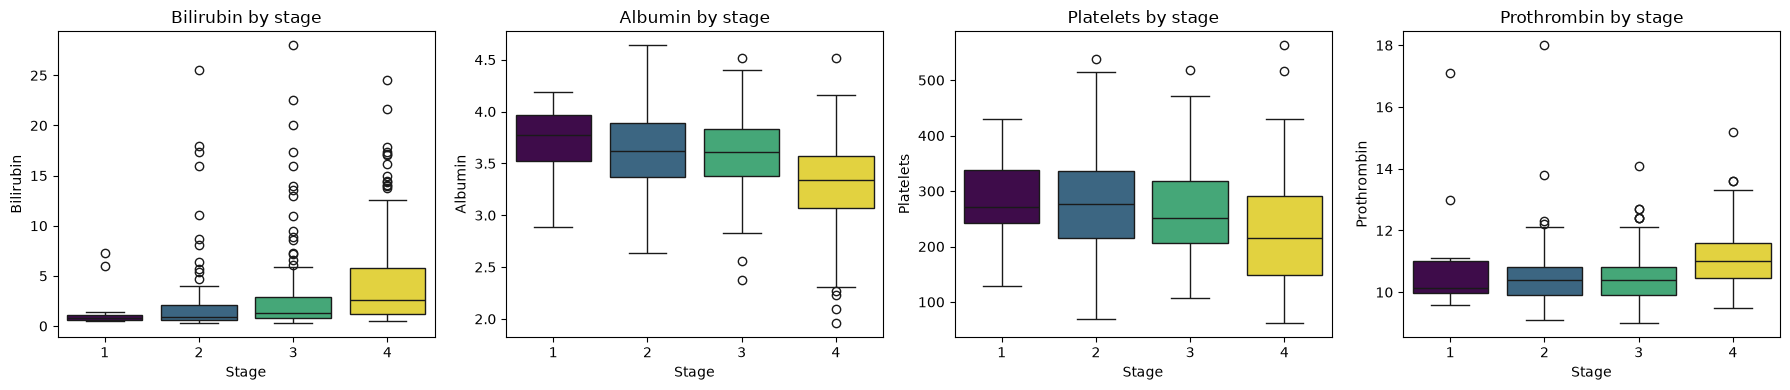

In [8]:
# Distribution of four tests by stage
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, column in zip(axes, ['Bilirubin', 'Albumin', 'Platelets', 'Prothrombin']):
    sns.boxplot(data=cirrhosis, x='Stage', y=column, ax=ax, hue='Stage', palette='viridis', legend=False)
    ax.set_title(column + ' by stage')
plt.tight_layout()
plt.show()

Each panel has one box per stage. The box holds the middle half of the patients, the line inside is the median, the whiskers reach the values still near the box and the dots beyond them are patients far from their group. The bilirubin boxes climb from left to right but every stage has dots far above, since a few patients in each stage have a bilirubin of 10 or 20. Albumin and platelets drift down with a large overlap between neighbouring stages. Prothrombin only separates stage 4, whose box sits visibly higher. In every panel the boxes of stages 2 and 3 cover each other almost entirely, which confirms what the medians said.

In [9]:
# Share of each stage among patients with and without each physical sign
for column in ['Ascites', 'Hepatomegaly', 'Spiders', 'Edema']:
    table = pd.crosstab(cirrhosis[column].fillna('unknown'), cirrhosis['Stage'], normalize='index') * 100
    print(table.round(1))
    print()

Stage      1     2     3     4
Ascites                       
N        5.6  22.6  41.3  30.6
Y        0.0   8.3   4.2  87.5
unknown  5.0  25.0  35.0  35.0

Stage            1     2     3     4
Hepatomegaly                        
N             10.5  31.6  44.1  13.8
Y              0.0  11.9  33.1  55.0
unknown        5.0  25.0  35.0  35.0

Stage      1     2     3     4
Spiders                       
N        6.8  26.1  40.5  26.6
Y        1.1  10.0  33.3  55.6
unknown  5.0  25.0  35.0  35.0

Stage    1     2     3     4
Edema                       
N      5.7  24.7  39.7  29.9
S      2.3  11.4  31.8  54.5
Y      0.0   5.0  15.0  80.0



Each table gives, for the patients with each value of a sign, the percentage that falls in each stage, so a row sums to 100. The signs are the strongest predictors in the file, and all of them point at stage 4. Of the patients with ascites, 87.5 percent are stage 4 against 30.6 percent of those without. With hepatomegaly the share of stage 4 rises from 13.8 to 55.0 percent, with spiders from 26.6 to 55.6, and with edema that does not respond to diuretics, the Y value, it reaches 80.0 percent. The unknown rows are the 106 patients outside the trial, whose stages are spread the same way as the whole file, so being outside the trial says nothing about the stage and the missing sign is recorded as a separate value rather than guessed.

In [10]:
# Preparation of the predictors
cirrhosis['Sex'] = (cirrhosis['Sex'] == 'M').astype(int)

# Each sign becomes two columns: 1 when present, and 1 when the sign was not recorded
SIGNS = ['Ascites', 'Hepatomegaly', 'Spiders']
for column in SIGNS:
    cirrhosis[column + '_yes'] = (cirrhosis[column] == 'Y').astype(int)
    cirrhosis[column + '_unknown'] = cirrhosis[column].isna().astype(int)

# Edema has three ordered values, so it is coded 0, 1, 2
EDEMA_CODES = {'N': 0, 'S': 1, 'Y': 2}
cirrhosis['Edema'] = cirrhosis['Edema'].map(EDEMA_CODES)

# The drug arm as two columns, patients outside the trial are 0 in both
cirrhosis['Drug_penicillamine'] = (cirrhosis['Drug'] == 'D-penicillamine').astype(int)
cirrhosis['Drug_placebo'] = (cirrhosis['Drug'] == 'Placebo').astype(int)

# Missing blood tests are filled with the median of the column. The fill values
# are kept so the API can apply the same ones
NUMERIC = ['Age'] + BLOOD_TESTS
FILL_VALUES = cirrhosis[NUMERIC].median()
cirrhosis[NUMERIC] = cirrhosis[NUMERIC].fillna(FILL_VALUES)

FEATURES = NUMERIC + ['Sex', 'Edema', 'Drug_penicillamine', 'Drug_placebo'] + \
           [c + '_yes' for c in SIGNS] + [c + '_unknown' for c in SIGNS]
TARGET = 'Stage'
print("Predictors:", len(FEATURES))
print("Missing values left:", int(cirrhosis[FEATURES].isna().sum().sum()))
cirrhosis[FEATURES + [TARGET]].head()

Predictors: 20
Missing values left: 0


,Age,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,...,Edema,Drug_penicillamine,Drug_placebo,Ascites_yes,Hepatomegaly_yes,Spiders_yes,Ascites_unknown,Hepatomegaly_unknown,Spiders_unknown,Stage
0,58.765229,14.5,261.0,2.60,156.0,1718.0,137.95,172.0,190.0,12.2,...,2,1,0,1,1,1,0,0,0,4
1,56.446270,1.1,302.0,4.14,54.0,7394.8,113.52,88.0,221.0,10.6,...,0,1,0,0,1,1,0,0,0,3
2,70.072553,1.4,176.0,3.48,210.0,516.0,96.10,55.0,151.0,12.0,...,1,1,0,0,0,0,0,0,0,4
3,54.740589,1.8,244.0,2.54,64.0,6121.8,60.63,92.0,183.0,10.3,...,1,1,0,0,1,1,0,0,0,4
4,38.105407,3.4,279.0,3.53,143.0,671.0,113.15,72.0,136.0,10.9,...,0,0,1,0,1,1,0,0,0,3


The table is now numeric with 20 predictors and no missing value. The median fill for the blood tests is a compromise: for the 106 patients outside the trial it places them at the middle of the file, and the `_unknown` columns tell the model that the signs of those patients were not observed, so it does not read a filled 0 as an absent sign.

In [11]:
# The scale of each predictor, which is what a distance-based model sees
scale = cirrhosis[FEATURES].std().sort_values(ascending=False)
print(scale.round(2))

Alk_Phos                1887.62
Cholesterol              194.47
Platelets                 94.47
Copper                    74.99
Tryglicerides             54.43
SGOT                      49.44
Age                       10.47
Bilirubin                  4.43
Prothrombin                1.02
Edema                      0.51
Hepatomegaly_yes           0.49
Drug_penicillamine         0.49
Drug_placebo               0.48
Hepatomegaly_unknown       0.43
Spiders_unknown            0.43
Ascites_unknown            0.43
Albumin                    0.42
Spiders_yes                0.41
Sex                        0.31
Ascites_yes                0.23
dtype: float64


The standard deviation of each column is its scale, and the radial kernel of the SVM compares two patients by the sum of the squared differences of every column, so a column with a large standard deviation dominates that sum. Alkaline phosphatase has a standard deviation above 1,800 and cholesterol near 190, while albumin has 0.42, prothrombin 1.0, and the 0 or 1 columns about 0.3 to 0.5. Without scaling, the distance between two patients would be almost entirely their difference in alkaline phosphatase, and the signs, which the exploration found to be the strongest predictors, would count for nothing. The pipeline below standardizes every column to a mean of 0 and a standard deviation of 1 before the SVM sees it, and the first model shows what happens when that step is skipped.

In [12]:
# Stratified 75 / 25 split, so the 21 stage 1 patients are shared in proportion
X = cirrhosis[FEATURES]
y = cirrhosis[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y)
print("Training patients:", len(X_train))
print(y_train.value_counts().sort_index())
print("Test patients:", len(X_test))
print(y_test.value_counts().sort_index())

Training patients: 309
Stage
1     16
2     69
3    116
4    108
Name: count, dtype: int64
Test patients: 103
Stage
1     5
2    23
3    39
4    36
Name: count, dtype: int64


Training keeps 309 patients and testing 103. The test set has 5 patients of stage 1, 23 of stage 2, 39 of stage 3 and 36 of stage 4. Five patients is a very small group, and every metric on stage 1 below is read with that in mind: one patient more or less moves its recall by twenty points.

## Machine Learning Model (CRISP-DM 4: Modeling)

Three models are fitted, all on the same training patients and scored on the same test patients. Model A is the SVM with the radial kernel and its default settings, first without scaling to show the damage and then inside a pipeline with the scaler. Model B keeps the scaler and searches C and gamma by cross-validation with balanced class weights, which is the literal four-stage classifier tuned as well as the data allows. Model C is the alternative the results of Model B call for, a two-class model that separates cirrhosis, stage 4, from the earlier stages.

### Model A: default SVM, without and with scaling

Model A without scaling
Accuracy: 0.369
Balanced accuracy: 0.247
              precision    recall  f1-score   support

           1       0.00      0.00      0.00         5
           2       0.00      0.00      0.00        23
           3       0.36      0.79      0.50        39
           4       0.41      0.19      0.26        36

    accuracy                           0.37       103
   macro avg       0.19      0.25      0.19       103
weighted avg       0.28      0.37      0.28       103



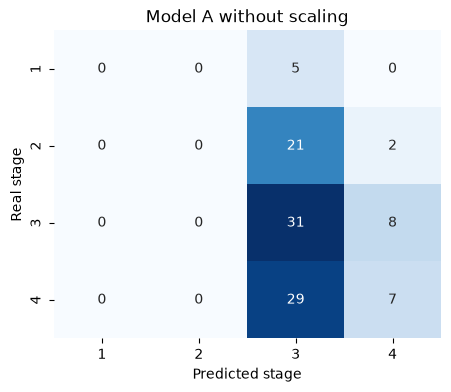

In [13]:
def report(model, X_eval, y_eval, name, labels):
    predicted = model.predict(X_eval)
    print(name)
    print("Accuracy: %.3f" % accuracy_score(y_eval, predicted))
    print("Balanced accuracy: %.3f" % balanced_accuracy_score(y_eval, predicted))
    print(classification_report(y_eval, predicted, zero_division=0))
    matrix = confusion_matrix(y_eval, predicted, labels=labels)
    plt.figure(figsize=(5, 4))
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=labels, yticklabels=labels)
    plt.xlabel('Predicted stage')
    plt.ylabel('Real stage')
    plt.title(name)
    plt.show()
    return predicted

STAGES = [1, 2, 3, 4]
model_unscaled = SVC(random_state=RANDOM_STATE).fit(X_train, y_train)
_ = report(model_unscaled, X_test, y_test, 'Model A without scaling', STAGES)

The classification report gives, per stage, the precision, which is the share of the patients predicted in that stage who really are, the recall, which is the share of the real patients of that stage the model found, their combination F1, and the support, the number of test patients of that stage. The confusion matrix has the real stage in rows and the predicted stage in columns, so the diagonal holds the correct predictions. Balanced accuracy is the average of the four recalls, and it is the score to watch here since it gives the five stage 1 patients the same weight as the thirty nine of stage 3.

Without scaling the model is useless. It predicts stage 3 for 86 of the 103 patients and stage 4 for the rest, never stage 1 or 2, for an accuracy of 0.369 and a balanced accuracy of 0.247, which is what guessing at random among four classes gives. The distances the kernel computed were dominated by alkaline phosphatase and cholesterol, and those two tests do not separate the stages.

Model A with scaling
Accuracy: 0.534
Balanced accuracy: 0.376
              precision    recall  f1-score   support

           1       0.00      0.00      0.00         5
           2       0.33      0.09      0.14        23
           3       0.47      0.64      0.54        39
           4       0.64      0.78      0.70        36

    accuracy                           0.53       103
   macro avg       0.36      0.38      0.35       103
weighted avg       0.48      0.53      0.48       103



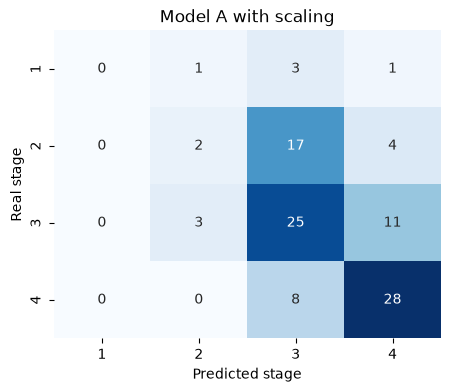

In [14]:
model_default = Pipeline([
    ('scale', StandardScaler()),
    ('svm', SVC(random_state=RANDOM_STATE)),
]).fit(X_train, y_train)
_ = report(model_default, X_test, y_test, 'Model A with scaling', STAGES)

Scaling alone lifts the accuracy from 0.369 to 0.534 and the balanced accuracy from 0.247 to 0.376. Stage 4 is now found 28 times out of 36, a recall of 0.78, and stage 3 25 times out of 39. But stage 2 is found twice out of 23 and stage 1 never, since with the default C of 1 and no class weights the model earns more by calling every uncertain patient stage 3 or 4, the two big classes. The next model tells it that the four stages weigh the same.

### Model B: grid search with balanced class weights

The search runs a five-fold stratified cross-validation, which the course covers with the SVM: the training patients are split in five parts, the model is fitted five times on four parts and scored on the fifth, and the average score decides. The score is the balanced accuracy, so a setting that ignores stage 1 is penalised. C runs from 0.1 to 100, where a small C accepts more misclassified training patients in exchange for a wider margin and a large C tries to fit every one of them, and gamma sets how far the influence of one patient reaches with the radial kernel.

In [15]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
GRID = {'svm__C': [0.1, 1, 10, 100], 'svm__gamma': ['scale', 0.01, 0.1]}

search_stage = GridSearchCV(
    Pipeline([('scale', StandardScaler()), ('svm', SVC(class_weight='balanced', random_state=RANDOM_STATE))]),
    GRID, cv=folds, scoring='balanced_accuracy', n_jobs=-1,
).fit(X_train, y_train)

print("Best setting:", search_stage.best_params_)
print("Cross-validated balanced accuracy: %.3f" % search_stage.best_score_)
results = pd.DataFrame(search_stage.cv_results_)[['param_svm__C', 'param_svm__gamma', 'mean_test_score']]
print(results.pivot(index='param_svm__C', columns='param_svm__gamma', values='mean_test_score').round(3))

Best setting: {'svm__C': 1, 'svm__gamma': 'scale'}
Cross-validated balanced accuracy: 0.443
param_svm__gamma   0.01    0.1  scale
param_svm__C                         
0.1               0.309  0.287  0.332
1.0               0.425  0.368  0.443
10.0              0.422  0.387  0.398
100.0             0.404  0.371  0.393


The pivot table gives the cross-validated balanced accuracy of every combination, with C in rows and gamma in columns. The best is C of 1 with gamma at scale, meaning one over the number of predictors, at 0.443. The whole table sits between 0.29 and 0.45, so no setting of the SVM turns this into a good four-class problem: the limit is in the data, not in the tuning. The worst row is C of 0.1, where the margin is so soft that the model barely separates anything, and the gamma of 0.1 column is below the others at every C, which is the model reaching too little and memorising the training patients.

Model B: tuned four-stage SVM
Accuracy: 0.447
Balanced accuracy: 0.424
              precision    recall  f1-score   support

           1       0.11      0.40      0.17         5
           2       0.29      0.26      0.27        23
           3       0.48      0.26      0.33        39
           4       0.67      0.78      0.72        36

    accuracy                           0.45       103
   macro avg       0.38      0.42      0.37       103
weighted avg       0.48      0.45      0.45       103



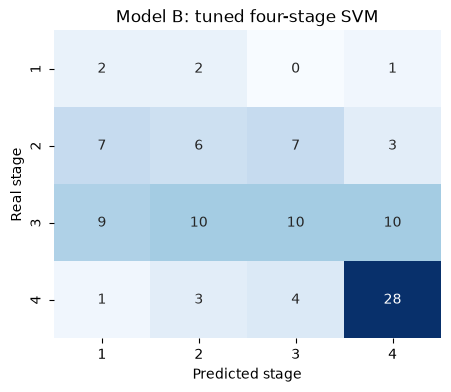

In [16]:
model_stage = search_stage.best_estimator_
predicted_stage = report(model_stage, X_test, y_test, 'Model B: tuned four-stage SVM', STAGES)

With balanced weights the model finally predicts all four stages. Stage 1 is found 2 times out of 5 and stage 2 6 times out of 23, so the balanced accuracy rises from 0.376 to 0.424. The price is paid by stage 3, whose recall drops from 0.64 to 0.26 because its patients are now spread across all four predictions, and the accuracy falls from 0.534 to 0.447. Stage 4 stays the reliable class, with 28 of 36 found and a precision of 0.67.

The matrix shows the shape of the failure. The errors are not random: stage 1 patients are called 2, stage 2 patients are called 1 or 3, stage 3 patients are spread over 2 and 4. The model is reading a single direction, how sick the liver looks in the blood, and the stages 1 to 3 sit too close together along it. This is the same conclusion the medians and the box plots reached, now measured. The literal task, four stages from a blood test, is answered by this model at a balanced accuracy of 0.424, and that is the honest number.

### Model C: cirrhosis against earlier stages

Everything in the exploration and in Model B says that stage 4 is the stage the blood and the signs can see. A two-class question, has this patient reached cirrhosis or not, is the question the data can answer, and it is also the one with the most clinical weight, since stage 4 is the point where treatment and monitoring change. The same pipeline and the same grid are run on the same training patients with the stages 1 to 3 merged.

Best setting: {'svm__C': 1, 'svm__gamma': 0.01}
Cross-validated balanced accuracy: 0.718
Model C: cirrhosis (1) against earlier stages (0)
Accuracy: 0.777
Balanced accuracy: 0.758
              precision    recall  f1-score   support

           0       0.83      0.82      0.83        67
           1       0.68      0.69      0.68        36

    accuracy                           0.78       103
   macro avg       0.75      0.76      0.76       103
weighted avg       0.78      0.78      0.78       103



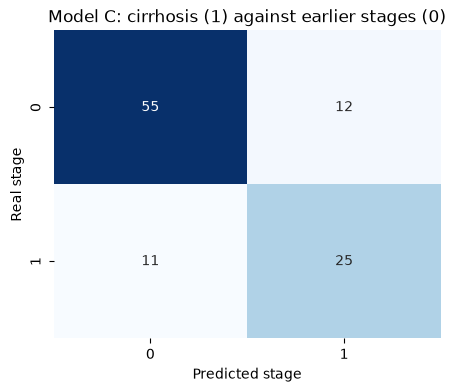

In [17]:
CIRRHOSIS_STAGE = 4
y_train_binary = (y_train == CIRRHOSIS_STAGE).astype(int)
y_test_binary = (y_test == CIRRHOSIS_STAGE).astype(int)

search_binary = GridSearchCV(
    Pipeline([('scale', StandardScaler()), ('svm', SVC(class_weight='balanced', random_state=RANDOM_STATE))]),
    GRID, cv=folds, scoring='balanced_accuracy', n_jobs=-1,
).fit(X_train, y_train_binary)
print("Best setting:", search_binary.best_params_)
print("Cross-validated balanced accuracy: %.3f" % search_binary.best_score_)

model_binary = search_binary.best_estimator_
BINARY_LABELS = [0, 1]
_ = report(model_binary, X_test, y_test_binary, 'Model C: cirrhosis (1) against earlier stages (0)', BINARY_LABELS)

The best setting is C of 1 with gamma 0.01, and the cross-validated balanced accuracy is 0.718, far above the 0.443 of the four-stage search. On the test patients the model reaches an accuracy of 0.777 and a balanced accuracy of 0.758: it finds 25 of the 36 patients with cirrhosis, a recall of 0.69, and correctly leaves alone 55 of the 67 without it, a recall of 0.82. Twelve earlier-stage patients are flagged as cirrhosis and eleven cirrhosis patients are missed. Those are real errors, but they are errors on a question the model can mostly answer, whereas the four-stage model was wrong more often than right.

## Evaluation (CRISP-DM 5)

The three models side by side, on the same 103 test patients. Model C answers a different question, so its numbers are not directly comparable with the other two, and the table says which question each one answers.

In [18]:
summary = pd.DataFrame({
    'Model A: default, scaled': {
        'Question': 'stage 1 to 4',
        'Accuracy': accuracy_score(y_test, model_default.predict(X_test)),
        'Balanced accuracy': balanced_accuracy_score(y_test, model_default.predict(X_test)),
    },
    'Model B: tuned, balanced': {
        'Question': 'stage 1 to 4',
        'Accuracy': accuracy_score(y_test, predicted_stage),
        'Balanced accuracy': balanced_accuracy_score(y_test, predicted_stage),
    },
    'Model C: cirrhosis or not': {
        'Question': 'stage 4 against 1 to 3',
        'Accuracy': accuracy_score(y_test_binary, model_binary.predict(X_test)),
        'Balanced accuracy': balanced_accuracy_score(y_test_binary, model_binary.predict(X_test)),
    },
}).T
summary[['Accuracy', 'Balanced accuracy']] = summary[['Accuracy', 'Balanced accuracy']].astype(float).round(3)
print(summary)

                                         Question  Accuracy  Balanced accuracy
Model A: default, scaled             stage 1 to 4     0.534              0.376
Model B: tuned, balanced             stage 1 to 4     0.447              0.424
Model C: cirrhosis or not  stage 4 against 1 to 3     0.777              0.758


Model A has the highest accuracy of the two four-stage models, 0.534 against 0.447, and that is stated before the choice between them. That accuracy comes from never predicting stage 1 and almost never stage 2, which is why its balanced accuracy is lower, 0.376 against 0.424. For a tool that is supposed to tell a patient their stage, ignoring two of the four stages is not acceptable, so Model B is the better four-stage model even though it is wrong more often overall. Model C reaches 0.777 and 0.758 on the two-class question, and the cost of that gain is stated plainly: it no longer tells stages 1, 2 and 3 apart, it only says whether the liver has reached cirrhosis.

## Results (CRISP-DM 6: Deployment)

The task asked for the type of cirrhosis, read here as the histologic stage from 1 to 4, and that model was built, tuned and evaluated. A support vector machine with a radial kernel, standardized predictors, balanced class weights, C of 1 and gamma at scale reaches an accuracy of 0.447 and a balanced accuracy of 0.424 on 103 unseen patients, with stage 4 found at a recall of 0.78 and the three earlier stages confused with each other. The data explains the result: the blood tests and the physical signs move mostly between stage 3 and stage 4, and the medians of stages 2 and 3 are the same on almost every test. Tuning could not fix that, since every setting of the grid stayed below a balanced accuracy of 0.45 in cross-validation.

The model kept for the assistant is Model C, which answers whether the patient has reached cirrhosis, with an accuracy of 0.777, a balanced accuracy of 0.758, a recall of 0.69 on cirrhosis and 0.82 on the earlier stages. The trade is the four-way stage in exchange for an answer that is right about three times in four instead of less than one in two. The four-stage model is saved next to it so the API can still return a stage when asked, with its limitation attached.

Two limitations apply to both. The data comes from a trial of 418 patients in the 1970s and 1980s, 89 percent of them women, and 106 of them have only the basic measurements, so a patient with a full set of blood tests is better served than one without. And no model here replaces a biopsy: a probability of cirrhosis from the blood is a reason to order one, not a diagnosis.

In [19]:
bundle = {
    'model': model_binary,
    'stage_model': model_stage,
    'features': FEATURES,
    'target': TARGET,
    'classes': {'model': {0: 'earlier stage', 1: 'cirrhosis'}, 'stage_model': STAGES},
    'fill_values': FILL_VALUES.to_dict(),
    'encoding': {'Sex': 'M=1', 'Edema': EDEMA_CODES, 'signs': 'Y=1 in _yes, missing=1 in _unknown',
                 'Drug': 'one column per arm, both 0 outside the trial', 'Age': 'years'},
}
MODEL_PATH = os.path.join(MODELS_DIR, 'cirrhosis_type_classification.joblib')
joblib.dump(bundle, MODEL_PATH)
print("Saved to", MODEL_PATH)

Saved to ../../models/cirrhosis_type_classification.joblib


In [20]:
# Reload and score one patient by hand: a 56 year old woman in the placebo arm
# with hepatomegaly and spiders, no ascites, mild edema, bilirubin 3.2,
# albumin 3.1, copper 120, platelets 150, prothrombin 11.5, other tests at the median
loaded = joblib.load(MODEL_PATH)
patient = pd.DataFrame([dict.fromkeys(loaded['features'], 0.0)])
for column, value in loaded['fill_values'].items():
    patient.loc[0, column] = value
patient.loc[0, ['Age', 'Bilirubin', 'Albumin', 'Copper', 'Platelets', 'Prothrombin']] = [56, 3.2, 3.1, 120, 150, 11.5]
patient.loc[0, ['Sex', 'Edema', 'Drug_placebo', 'Hepatomegaly_yes', 'Spiders_yes']] = [0, 1, 1, 1, 1]

print("Cirrhosis:", loaded['classes']['model'][int(loaded['model'].predict(patient)[0])])
print("Stage:", int(loaded['stage_model'].predict(patient)[0]))

Cirrhosis: cirrhosis
Stage: 4


The reloaded models call this patient cirrhosis and stage 4, which is what her profile, a high bilirubin, a low albumin, low platelets, a long prothrombin time and two physical signs, points to. The REST API repeats this call: fill the 20 columns with the stored fill values, overwrite the ones the user provides, and return both answers.